# AI-Driven Network Operations Simulation

A reproducible, synthetic demonstration of three network-operations ideas: moving-average capacity estimation, offline anomaly detection with an Isolation Forest, and rule-based responses to threats or high latency. It is an educational simulation, not a production network controller or a real-time zero-day detector.

1. **Traffic estimation**: Compares bandwidth measurements with a trailing moving-average estimate.
2. **Anomaly detection**: Trains on separate synthetic normal traffic and evaluates a sample containing known injected anomalies.
3. **AIOps policy simulation**: Applies deterministic rate-limit or rerouting actions to flagged threats and simulated link failures.

Run the code cells from top to bottom. Results are reproducible for a given random seed.

## Simulation and Evaluation
The model is fitted on a separate normal-only baseline, then evaluated against a synthetic sample with explicitly labeled injected anomalies. Reported precision and recall describe this generated example only; they are not evidence of production detection performance.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_score, recall_score


class ProAINetworkSimulator:
    """Reproducible synthetic simulation of traffic, anomalies, and response policies."""

    ATTACK_INDICES = (45, 120, 230)
    FAILURE_INDICES = (85, 195)

    def __init__(self, n_samples: int = 300, random_seed: int = 42) -> None:
        if n_samples <= max(*self.ATTACK_INDICES, *self.FAILURE_INDICES):
            raise ValueError("n_samples must be at least 231 for the configured events.")
        if random_seed < 0:
            raise ValueError("random_seed must be non-negative.")

        self.n_samples = n_samples
        self.random_seed = random_seed
        self.df: pd.DataFrame | None = None

    def run_traffic_optimization_pipeline(self) -> None:
        """Create synthetic traffic and a leak-free trailing moving-average estimate."""
        rng = np.random.default_rng(self.random_seed)
        time_steps = np.arange(self.n_samples)
        base_traffic = (
            100
            + 25 * np.sin(time_steps / 10)
            + rng.normal(0, 5, self.n_samples)
        )
        bandwidth = np.clip(base_traffic, 10, 200)
        self.df = pd.DataFrame({
            "Time_Step": time_steps,
            "Bandwidth_Mbps": bandwidth,
        })
        history = self.df["Bandwidth_Mbps"].shift(1)
        self.df["Predicted_Demand_Mbps"] = (
            history.rolling(window=5, min_periods=1).mean().fillna(100.0) * 1.05
        )
        print("Module 1 complete: synthetic traffic and trailing estimate created.")

    def run_security_anomalies_pipeline(self) -> None:
        """Fit on normal baseline data and score a separate labeled synthetic sample."""
        if self.df is None:
            raise RuntimeError("Run the traffic pipeline before anomaly detection.")

        rng = np.random.default_rng(self.random_seed + 1)
        baseline_size = max(1000, self.n_samples)
        baseline = pd.DataFrame({
            "Packet_Size": rng.normal(512, 50, baseline_size),
            "Packet_Rate": rng.normal(50, 10, baseline_size),
        })
        packet_sizes = rng.normal(512, 50, self.n_samples)
        packet_rates = rng.normal(50, 10, self.n_samples)
        true_threat = np.zeros(self.n_samples, dtype=bool)

        for index in self.ATTACK_INDICES:
            packet_sizes[index] = 3500
            packet_rates[index] = 950
            true_threat[index] = True

        self.df["Packet_Size"] = packet_sizes
        self.df["Packet_Rate"] = packet_rates
        self.df["True_Threat"] = true_threat

        model = IsolationForest(contamination=0.001, random_state=self.random_seed)
        model.fit(baseline)
        scores = model.predict(self.df[["Packet_Size", "Packet_Rate"]])
        self.df["Security_Score"] = scores
        self.df["Threat_Status"] = np.where(
            scores == -1, "ALERT: Threat Detected", "Normal"
        )
        print("Module 2 complete: model trained on separate normal-only baseline.")

    def run_self_healing_aiops_pipeline(self, latency_threshold_ms: float = 80.0) -> None:
        """Apply threat-first and then latency-based actions to the synthetic telemetry."""
        if self.df is None or "Threat_Status" not in self.df:
            raise RuntimeError("Run the traffic and security pipelines first.")
        if latency_threshold_ms <= 0:
            raise ValueError("latency_threshold_ms must be positive.")

        rng = np.random.default_rng(self.random_seed + 2)
        latency = rng.uniform(10, 45, self.n_samples)
        link_failure = np.zeros(self.n_samples, dtype=bool)
        for index in self.FAILURE_INDICES:
            latency[index] = 145.0
            link_failure[index] = True

        self.df["Link_Latency_ms"] = latency
        self.df["Link_Failure"] = link_failure
        conditions = [
            self.df["Threat_Status"].eq("ALERT: Threat Detected"),
            self.df["Link_Latency_ms"].gt(latency_threshold_ms),
        ]
        actions = [
            "Drop & Rate-Limit",
            "Reroute via Backup Node (Self-Healing QoS)",
        ]
        self.df["AIOps_Action"] = np.select(
            conditions, actions, default="Optimal Routing"
        )
        print("Module 3 complete: threat and latency policies applied.")


simulator = ProAINetworkSimulator(n_samples=300, random_seed=42)
simulator.run_traffic_optimization_pipeline()
simulator.run_security_anomalies_pipeline()
simulator.run_self_healing_aiops_pipeline()

actual = simulator.df["True_Threat"]
predicted = simulator.df["Threat_Status"].eq("ALERT: Threat Detected")
print("\nSynthetic detection check")
print(f"Injected threats: {int(actual.sum())}")
print(f"Threat alerts: {int(predicted.sum())}")
print(f"Precision: {precision_score(actual, predicted, zero_division=0):.2f}")
print(f"Recall: {recall_score(actual, predicted, zero_division=0):.2f}")
display(simulator.df[[
    "Time_Step", "Bandwidth_Mbps", "Predicted_Demand_Mbps",
    "True_Threat", "Threat_Status", "Link_Latency_ms", "AIOps_Action",
]].tail(10))

Module 1 complete: synthetic traffic and trailing estimate created.
Module 2 complete: model trained on separate normal-only baseline.
Module 3 complete: threat and latency policies applied.

Synthetic detection check
Injected threats: 3
Threat alerts: 3
Precision: 1.00
Recall: 1.00


,Time_Step,Bandwidth_Mbps,Predicted_Demand_Mbps,True_Threat,Threat_Status,Link_Latency_ms,AIOps_Action
290,290,82.149266,93.690188,False,Normal,15.968626,Optimal Routing
291,291,82.387822,91.611352,False,Normal,13.817600,Optimal Routing
292,292,87.381923,89.315577,False,Normal,22.600742,Optimal Routing
293,293,65.790213,88.778560,False,Normal,21.228959,Optimal Routing
294,294,76.251883,84.535678,False,Normal,31.021935,Optimal Routing
295,295,77.356777,82.731833,False,Normal,28.349456,Optimal Routing
296,296,77.227327,81.725410,False,Normal,38.090864,Optimal Routing
297,297,73.403250,80.641706,False,Normal,21.069320,Optimal Routing
298,298,66.241846,77.706185,False,Normal,12.406586,Optimal Routing
299,299,76.677602,77.801027,False,Normal,35.189442,Optimal Routing


In [ ]:
expected_alert = "ALERT: Threat Detected"
expected_reroute = "Reroute via Backup Node (Self-Healing QoS)"

assert simulator.df.loc[list(simulator.ATTACK_INDICES), "Threat_Status"].eq(expected_alert).all()
assert not simulator.df.loc[~simulator.df["True_Threat"], "Threat_Status"].eq(expected_alert).any()
assert simulator.df.loc[list(simulator.FAILURE_INDICES), "AIOps_Action"].eq(expected_reroute).all()
print("All synthetic scenario checks passed.")

All synthetic scenario checks passed.


## Synthetic Telemetry Dashboard
The plots show the generated traffic, model alerts compared with injected ground-truth events, and the policy actions triggered by the simulated telemetry.

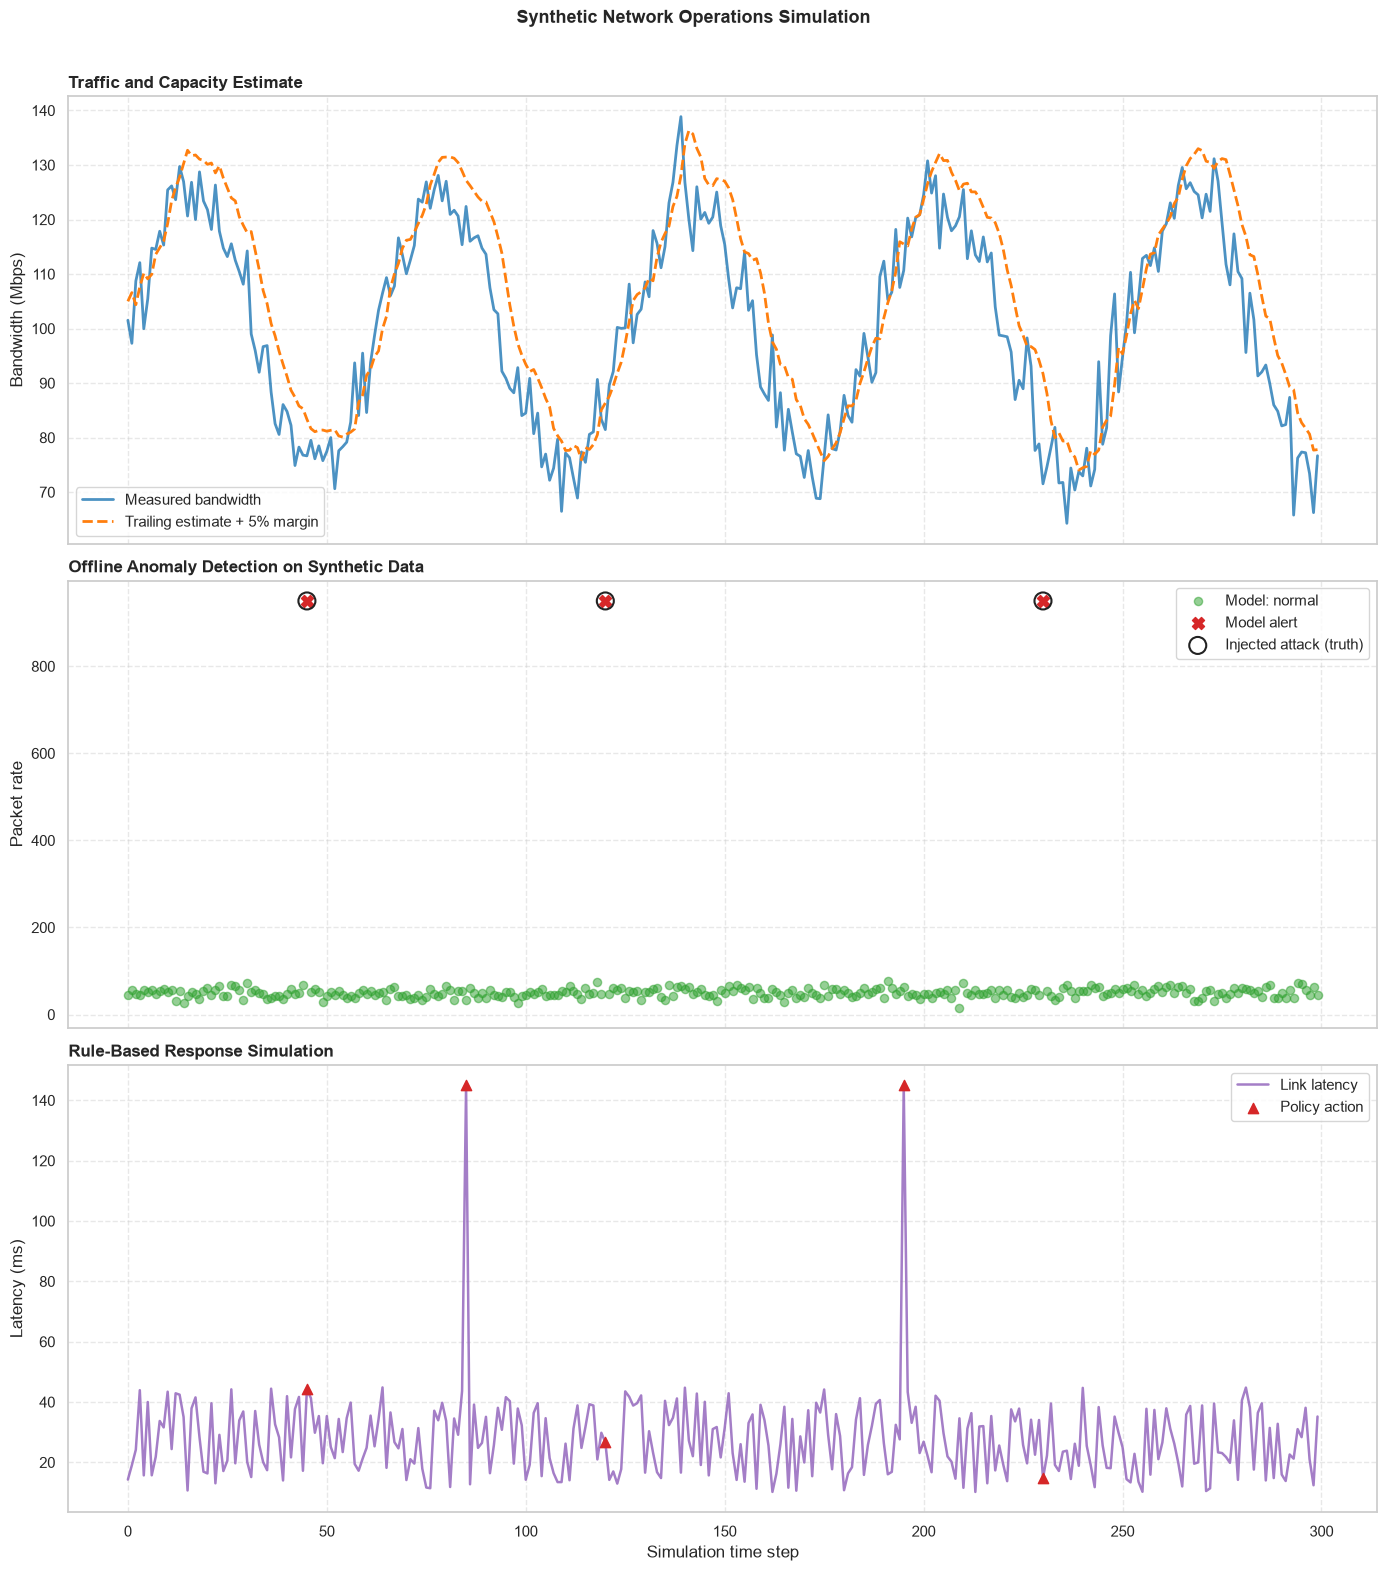

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["font.size"] = 11

fig, axes = plt.subplots(3, 1, figsize=(14, 16), sharex=True)
colors = {
    "primary": "#1f77b4",
    "secondary": "#ff7f0e",
    "success": "#2ca02c",
    "danger": "#d62728",
    "highlight": "#9467bd",
    "truth": "#222222",
}

# Traffic estimation
axes[0].plot(
    simulator.df["Time_Step"], simulator.df["Bandwidth_Mbps"],
    color=colors["primary"], label="Measured bandwidth", alpha=0.8, linewidth=2,
)
axes[0].plot(
    simulator.df["Time_Step"], simulator.df["Predicted_Demand_Mbps"],
    color=colors["secondary"], label="Trailing estimate + 5% margin",
    linestyle="--", linewidth=2,
)
axes[0].set_title("Traffic and Capacity Estimate", loc="left", fontweight="bold")
axes[0].set_ylabel("Bandwidth (Mbps)")
axes[0].legend()

# Model alerts and known synthetic attack locations
normal_traffic = simulator.df[~simulator.df["Threat_Status"].eq("ALERT: Threat Detected")]
threat_traffic = simulator.df[simulator.df["Threat_Status"].eq("ALERT: Threat Detected")]
true_threats = simulator.df[simulator.df["True_Threat"]]
axes[1].scatter(
    normal_traffic["Time_Step"], normal_traffic["Packet_Rate"],
    color=colors["success"], label="Model: normal", alpha=0.5, s=35,
)
axes[1].scatter(
    threat_traffic["Time_Step"], threat_traffic["Packet_Rate"],
    color=colors["danger"], label="Model alert", marker="X", s=75, zorder=4,
)
axes[1].scatter(
    true_threats["Time_Step"], true_threats["Packet_Rate"],
    facecolors="none", edgecolors=colors["truth"], label="Injected attack (truth)",
    marker="o", s=150, linewidths=1.5, zorder=5,
)
axes[1].set_title("Offline Anomaly Detection on Synthetic Data", loc="left", fontweight="bold")
axes[1].set_ylabel("Packet rate")
axes[1].legend()

# Simulated response actions
axes[2].plot(
    simulator.df["Time_Step"], simulator.df["Link_Latency_ms"],
    color=colors["highlight"], label="Link latency", alpha=0.85, linewidth=1.8,
)
a_ops_actions = simulator.df[simulator.df["AIOps_Action"].ne("Optimal Routing")]
axes[2].scatter(
    a_ops_actions["Time_Step"], a_ops_actions["Link_Latency_ms"],
    color=colors["danger"], label="Policy action", s=55, marker="^", zorder=5,
)
axes[2].set_title("Rule-Based Response Simulation", loc="left", fontweight="bold")
axes[2].set_xlabel("Simulation time step")
axes[2].set_ylabel("Latency (ms)")
axes[2].legend()

for axis in axes:
    axis.grid(True, linestyle="--", alpha=0.45)

fig.suptitle("Synthetic Network Operations Simulation", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()